# Topic 4: Sampling Distributions and the Central Limit Theorem
**BIT 4131** | Dataset: UCI Student Performance (Portuguese course, n = 649)

---
## 1. Theoretical explanation
- A **statistic** (e.g. the sample mean) changes from sample to sample. Its **sampling distribution** is the distribution of that statistic over all possible samples of size $n$.
- The **standard error (SE)** is the standard deviation of that sampling distribution. It shrinks as $n$ grows.
- The **Central Limit Theorem (CLT)** says that for independent samples from *any* population with finite variance, the sampling distribution of $\bar{X}$ becomes approximately normal as $n$ grows, even if the population is not normal.
- We treat the 649 students as a **finite population** and draw repeated random samples from it. That lets us compare the simulated result with the theory exactly.

---
## 2. Mathematical formulation
If $X_1,\dots,X_n$ are i.i.d. with mean $\mu$ and variance $\sigma^2$:

$$E[\bar X]=\mu \qquad \operatorname{Var}(\bar X)=\frac{\sigma^2}{n} \qquad SE(\bar X)=\frac{\sigma}{\sqrt n}$$

$$\frac{\bar X-\mu}{\sigma/\sqrt n}\ \xrightarrow{d}\ N(0,1)\quad (n\to\infty)$$

When $\sigma$ is unknown, the estimated standard error is $\widehat{SE}=s/\sqrt n$.
For sampling *without replacement* from a finite population of size $N$ there is a correction, $SE=\frac{\sigma}{\sqrt n}\sqrt{\frac{N-n}{N-1}}$, which is negligible when $n\ll N$. Here we sample with replacement so the plain formula applies exactly.

---
## 3. Worked example
A tiny population `{2, 4, 6, 8}`. List every possible sample of size 2 (with replacement), compute each mean, and check the theory.

In [1]:
import itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

pop = np.array([2, 4, 6, 8])
mu, sigma = pop.mean(), pop.std(ddof=0)          # population parameters
samples = list(itertools.product(pop, repeat=2)) # 16 equally likely samples
means = np.array([np.mean(s) for s in samples])

print("All 16 sample means:", means)
print(f"Population mean mu = {mu}, sigma = {sigma:.4f}")
print(f"Mean of sample means      = {means.mean():.4f}  (theory: mu = {mu})")
print(f"SD of sample means (SE)   = {means.std(ddof=0):.4f}  (theory: sigma/sqrt(2) = {sigma/np.sqrt(2):.4f})")

All 16 sample means: [2. 3. 4. 5. 3. 4. 5. 6. 4. 5. 6. 7. 5. 6. 7. 8.]
Population mean mu = 5.0, sigma = 2.2361
Mean of sample means      = 5.0000  (theory: mu = 5.0)
SD of sample means (SE)   = 1.5811  (theory: sigma/sqrt(2) = 1.5811)


---
## 4. Dataset analysis
Population = all 649 final grades `G3`. We also use `absences`, which is strongly right-skewed, to show that the CLT works even for a very non-normal variable.

In [2]:
df = pd.read_csv("../data/student-por.csv", sep=";")
rng = np.random.default_rng(4131)               # fixed seed for reproducibility

def sampling_dist(values, n, reps=5000):
    # `reps` sample means, each from a sample of size n drawn with replacement
    return rng.choice(values, size=(reps, n), replace=True).mean(axis=1)

OUT = []   # collects the results for the section-5 summary

def report(name, values, sizes=(2, 5, 30, 100)):
    mu, sigma = values.mean(), values.std(ddof=0)
    rows = []
    for n in sizes:
        m = sampling_dist(values, n)
        rows.append({"n": n, "mean of x-bar": m.mean(), "SE (simulated)": m.std(ddof=1),
                     "SE (theory sigma/sqrt n)": sigma / np.sqrt(n), "skewness of x-bar": stats.skew(m)})
    print(f"{name}: population mu = {mu:.3f}, sigma = {sigma:.3f}, skewness = {stats.skew(values):.3f}")
    print(pd.DataFrame(rows).round(3).to_string(index=False), "\n")
    OUT.extend({"variable": name, **r} for r in rows)

g3 = df["G3"].to_numpy()
ab = df["absences"].to_numpy()
report("G3", g3)
report("absences", ab)

G3: population mu = 11.906, sigma = 3.228, skewness = -0.911
  n  mean of x-bar  SE (simulated)  SE (theory sigma/sqrt n)  skewness of x-bar
  2         11.965           2.244                     2.283             -0.620
  5         11.911           1.437                     1.444             -0.443
 30         11.909           0.591                     0.589             -0.213
100         11.909           0.321                     0.323             -0.142 

absences: population mu = 3.659, sigma = 4.637, skewness = 2.016
  n  mean of x-bar  SE (simulated)  SE (theory sigma/sqrt n)  skewness of x-bar
  2          3.673           3.290                     3.279              1.431
  5          3.686           2.083                     2.074              0.938
 30          3.655           0.847                     0.847              0.344
100          3.650           0.458                     0.464              0.234 



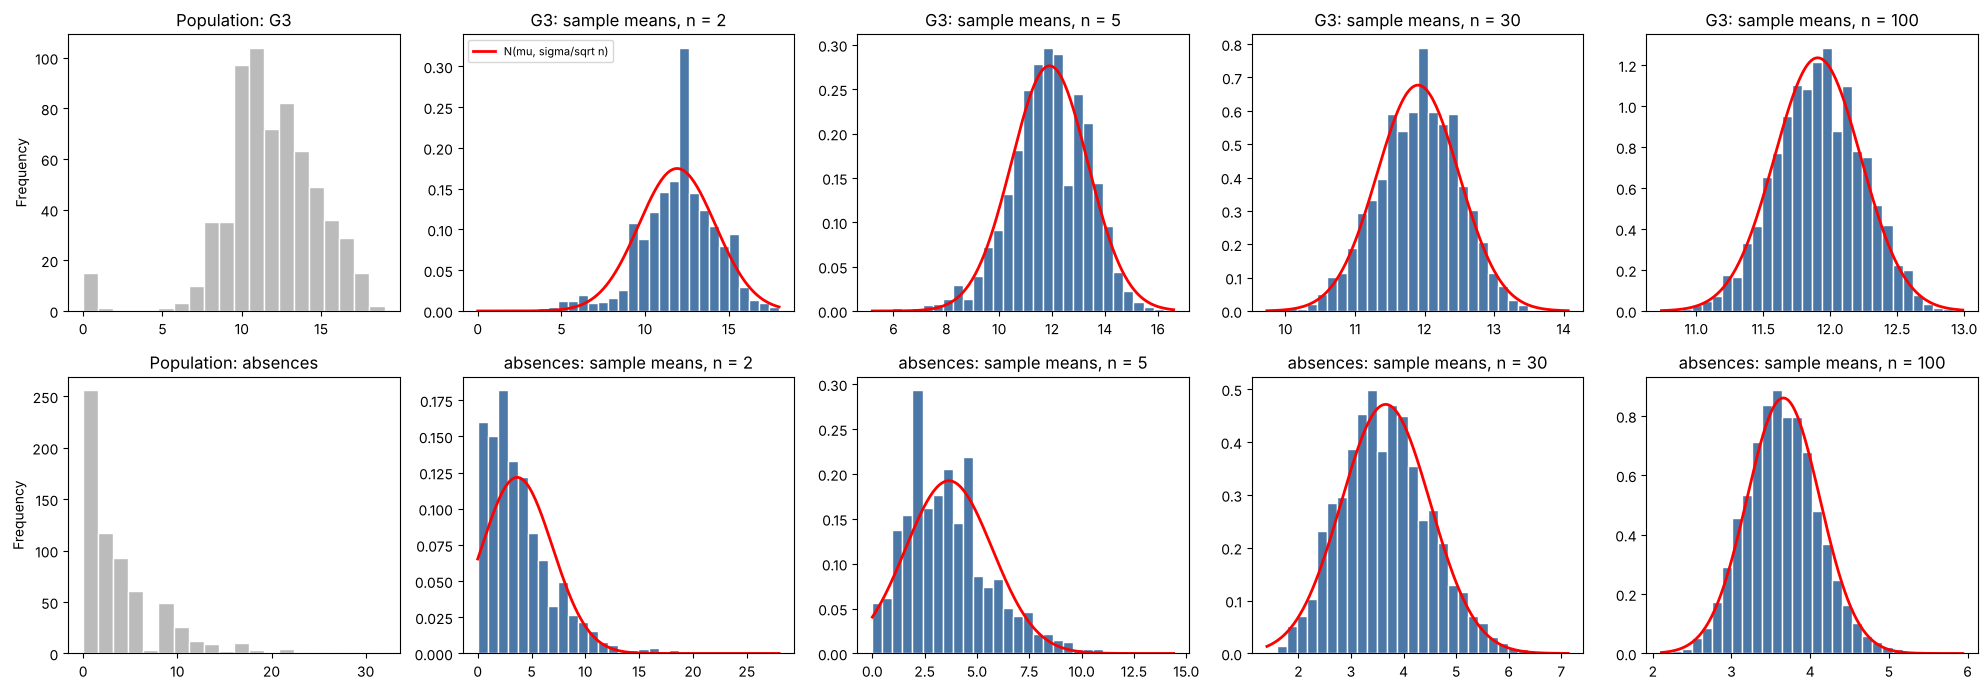

In [3]:
sizes = [2, 5, 30, 100]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for row, (name, vals) in enumerate([("G3", g3), ("absences", ab)]):
    axes[row, 0].hist(vals, bins=20, color="#bbbbbb", edgecolor="white")
    axes[row, 0].set(title=f"Population: {name}", ylabel="Frequency")
    for col, n in enumerate(sizes, start=1):
        m = sampling_dist(vals, n)
        ax = axes[row, col]
        ax.hist(m, bins=30, density=True, color="#4C78A8", edgecolor="white")
        xs = np.linspace(m.min(), m.max(), 200)
        ax.plot(xs, stats.norm.pdf(xs, vals.mean(), vals.std(ddof=0) / np.sqrt(n)), "r-", lw=2,
                label="N(mu, sigma/sqrt n)")
        ax.set(title=f"{name}: sample means, n = {n}")
        if row == 0 and col == 1: ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/t04_clt_g3_absences.png", dpi=130)
plt.show()

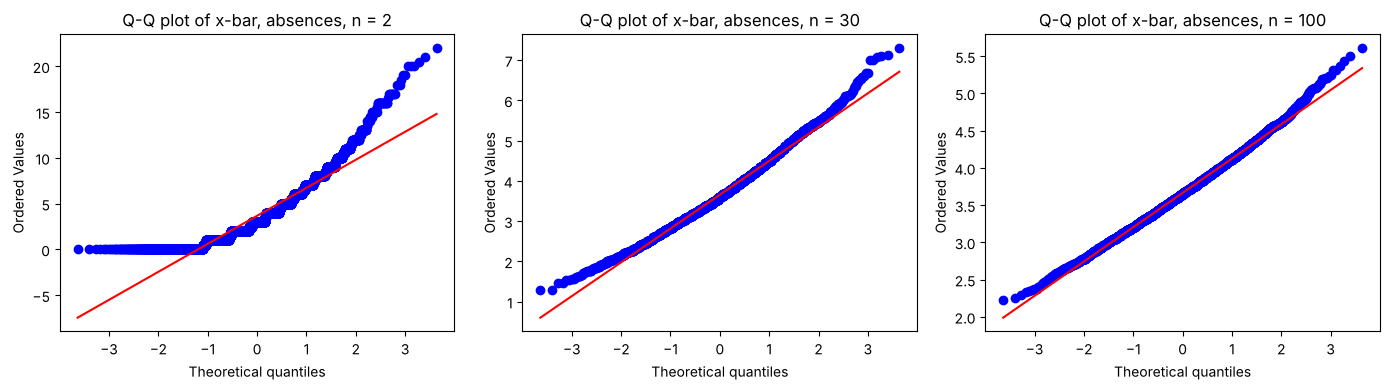

In [4]:
# Normality check of the sampling distribution via Q-Q plot (absences, the harder case)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, n in zip(axes, [2, 30, 100]):
    stats.probplot(sampling_dist(ab, n), dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot of x-bar, absences, n = {n}")
plt.tight_layout()
plt.savefig("figures/t04_qq_absences.png", dpi=130)
plt.show()

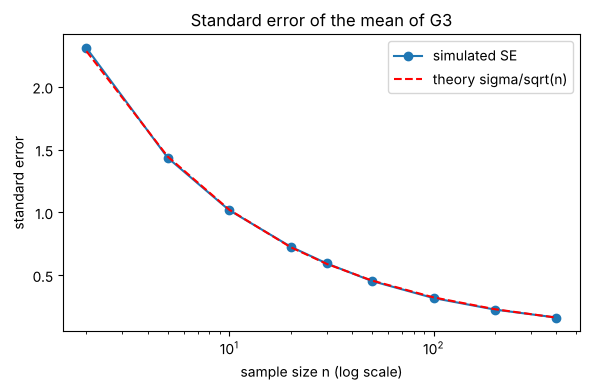

In [5]:
# SE shrinks like 1/sqrt(n)
ns = np.array([2, 5, 10, 20, 30, 50, 100, 200, 400])
se_sim = [sampling_dist(g3, n).std(ddof=1) for n in ns]
plt.figure(figsize=(6, 4))
plt.plot(ns, se_sim, "o-", label="simulated SE")
plt.plot(ns, g3.std(ddof=0) / np.sqrt(ns), "r--", label="theory sigma/sqrt(n)")
plt.xscale("log"); plt.xlabel("sample size n (log scale)"); plt.ylabel("standard error")
plt.title("Standard error of the mean of G3"); plt.legend(); plt.tight_layout()
plt.savefig("figures/t04_se_vs_n.png", dpi=130)
plt.show()

---
## 5. Expected statistical output
Sampling distribution of the mean for each sample size: centre, simulated standard error versus the theoretical $\sigma/\sqrt n$, and shape (skewness). Histograms with the normal curve, Q-Q plots and the SE-versus-$n$ curve are saved in `figures/`.

In [6]:
summary = pd.DataFrame(OUT).round(3)
summary["SE gap (%)"] = ((summary["SE (simulated)"] / summary["SE (theory sigma/sqrt n)"] - 1) * 100).round(1)
print(summary.to_string(index=False))

variable   n  mean of x-bar  SE (simulated)  SE (theory sigma/sqrt n)  skewness of x-bar  SE gap (%)
      G3   2         11.965           2.244                     2.283             -0.620        -1.7
      G3   5         11.911           1.437                     1.444             -0.443        -0.5
      G3  30         11.909           0.591                     0.589             -0.213         0.3
      G3 100         11.909           0.321                     0.323             -0.142        -0.6
absences   2          3.673           3.290                     3.279              1.431         0.3
absences   5          3.686           2.083                     2.074              0.938         0.4
absences  30          3.655           0.847                     0.847              0.344         0.0
absences 100          3.650           0.458                     0.464              0.234        -1.3


---
## 6. Interpretation of results

In [7]:
m2, m100 = sampling_dist(ab, 2), sampling_dist(ab, 100)
print(f"1. Unbiasedness: for every n the mean of the sample means is within a few hundredths of the population mean.")
print(f"2. Standard error: simulated SE tracks sigma/sqrt(n) closely, e.g. G3 with n = 30 is {sampling_dist(g3,30).std(ddof=1):.3f} "
      f"vs theory {g3.std(ddof=0)/np.sqrt(30):.3f}. Quadrupling n halves the SE.")
print(f"3. CLT: 'absences' is strongly right-skewed (skewness {stats.skew(ab):.2f}). Means of n = 2 are still skewed ({stats.skew(m2):.2f}) "
      f"but at n = 100 the skewness is down to {stats.skew(m100):.2f} and the histogram follows the normal curve.")
g30 = sampling_dist(g3, 30)
print(f"4. G3 is only moderately left-skewed ({stats.skew(g3):.2f}), so its sample means are already close to normal by n = 30 (skewness {stats.skew(g30):.2f}).")

1. Unbiasedness: for every n the mean of the sample means is within a few hundredths of the population mean.
2. Standard error: simulated SE tracks sigma/sqrt(n) closely, e.g. G3 with n = 30 is 0.589 vs theory 0.589. Quadrupling n halves the SE.
3. CLT: 'absences' is strongly right-skewed (skewness 2.02). Means of n = 2 are still skewed (1.42) but at n = 100 the skewness is down to 0.18 and the histogram follows the normal curve.
4. G3 is only moderately left-skewed (-0.91), so its sample means are already close to normal by n = 30 (skewness -0.15).


**Take-aways**
- Sample means are centred on the population mean and their spread falls as $1/\sqrt n$.
- The more skewed the population, the larger $n$ must be before normality is a good approximation; $n\ge 30$ is a rule of thumb, not a guarantee.
- This is the justification for the confidence intervals (Topic 5) and tests (Topic 6) that follow.